CSV file created successfully:
handover_log.csv


              HANDOVER ANALYSIS REPORT
Total route duration : 80 seconds
Total samples        : 17
Different cells      : 2
Total handovers      : 6
Handover rate        : 4.50 per minute


HANDOVER DETAILS
-----------------------------------------------------------------
Time 25s : 12345 -> 67890 | Margin = +5 dB | Healthy
Time 35s : 67890 -> 12345 | Margin = -2 dB | Unjustified
Time 50s : 12345 -> 67890 | Margin = +2 dB | Weak Margin
Time 65s : 67890 -> 12345 | Margin = +4 dB | Healthy
Time 80s : 12345 -> 67890 | Margin = +4 dB | Healthy
Time 90s : 67890 -> 12345 | Margin = -4 dB | Unjustified


DWELL TIME PER CELL
-----------------------------------------------------------------
Cell 12345 : 45 seconds
Cell 67890 : 35 seconds


PING-PONG ANALYSIS
-----------------------------------------------------------------
Ping-pong events detected: 5
12345 -> 67890 -> 12345 | Time gap = 10s
67890 -> 12345 -> 67890 | Time gap = 15s
12345 -> 6789

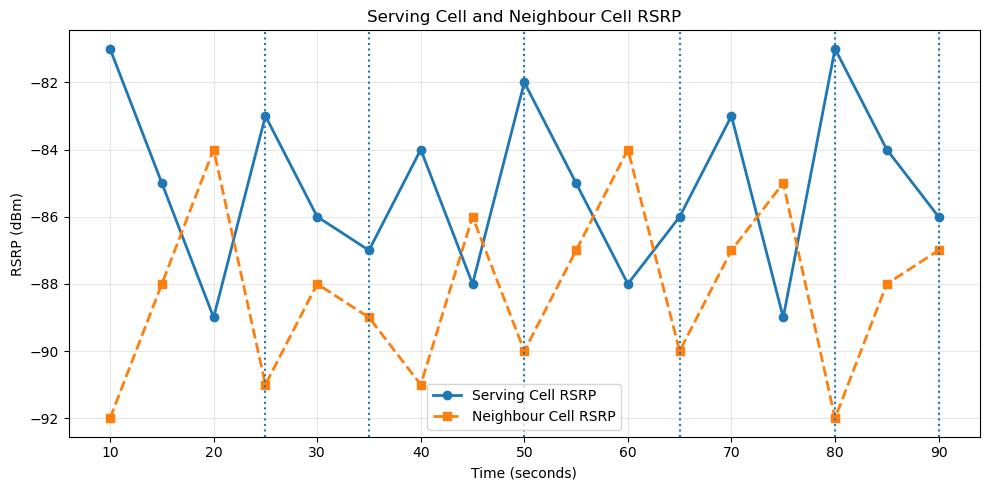

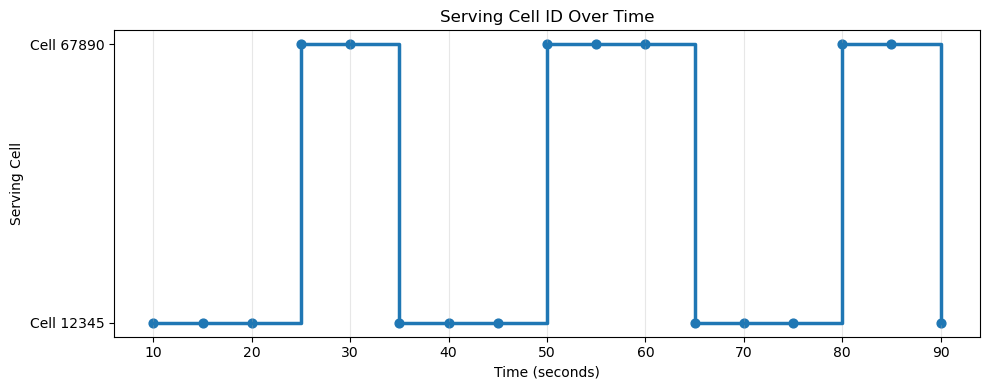

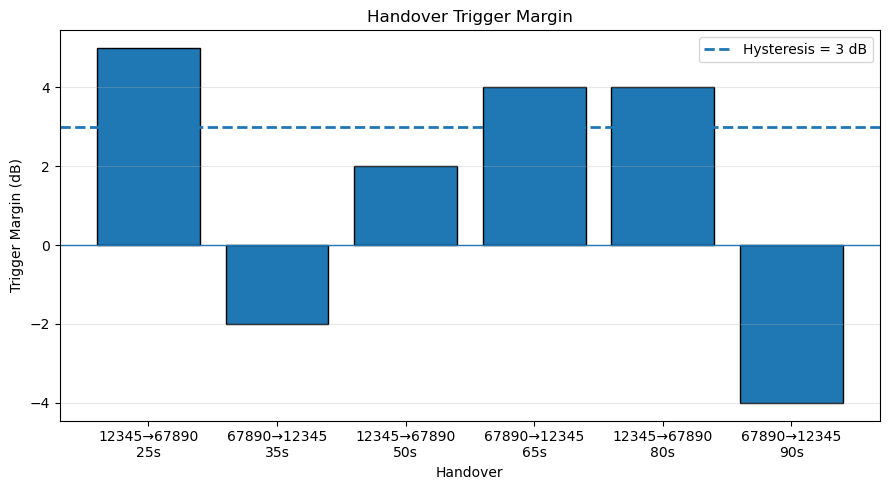

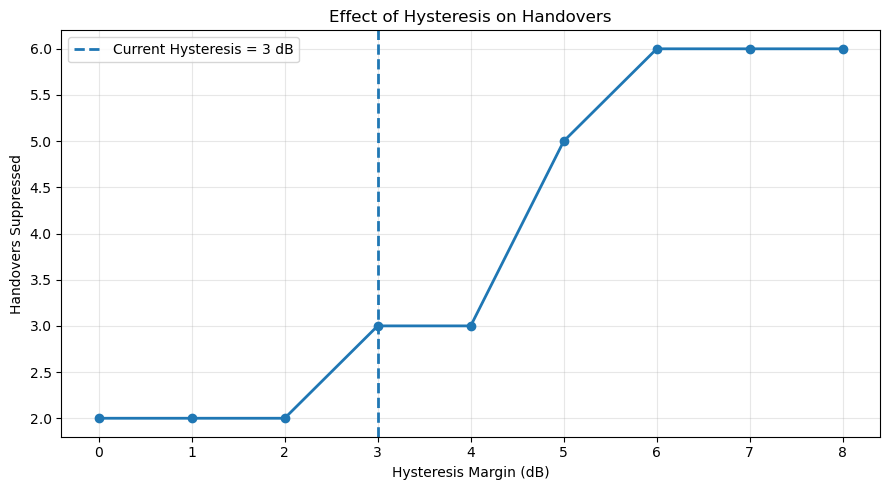



              ANALYSIS COMPLETED
CSV file:
handover_log.csv

Generated graphs:
1. handover_rsrp_timeline.png
2. handover_cell_timeline.png
3. handover_margins.png
4. hysteresis_sweep.png


In [1]:
# ============================================================
# HANDOVER BEHAVIOUR ANALYSIS WHILE MOVING
# Complete Google Colab Code
# ============================================================

import csv
import os
from collections import OrderedDict
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# SETTINGS
# ============================================================

HYSTERESIS_DB = 3.0
PING_PONG_WINDOW_S = 20.0


# ============================================================
# CSV DATA
# Changed according to the given handover values
# ============================================================

CSV_DATA = """Time_s,ServingCellID,ServingRSRP_dBm,NeighborCellID,NeighborRSRP_dBm
10,12345,-81,67890,-92
15,12345,-85,67890,-88
20,12345,-89,67890,-84
25,67890,-83,12345,-91
30,67890,-86,12345,-88
35,12345,-87,67890,-89
40,12345,-84,67890,-91
45,12345,-88,67890,-86
50,67890,-82,12345,-90
55,67890,-85,12345,-87
60,67890,-88,12345,-84
65,12345,-86,67890,-90
70,12345,-83,67890,-87
75,12345,-89,67890,-85
80,67890,-81,12345,-92
85,67890,-84,12345,-88
90,12345,-86,67890,-87
"""


# ============================================================
# CREATE CSV FILE
# ============================================================

csv_file = "handover_log.csv"

with open(csv_file, "w") as file:
    file.write(CSV_DATA)

print("CSV file created successfully:")
print(csv_file)


# ============================================================
# LOAD CSV DATA
# ============================================================

def load_log(filename):

    rows = []

    with open(filename, "r") as file:

        reader = csv.reader(file)

        for row in reader:

            if not row:
                continue

            if row[0].strip() == "Time_s":
                continue

            rows.append({
                "t": float(row[0]),
                "cell": row[1].strip(),
                "rsrp": float(row[2]),
                "ncell": row[3].strip(),
                "nrsrp": float(row[4])
            })

    return sorted(rows, key=lambda x: x["t"])


# ============================================================
# DETECT HANDOVERS
# ============================================================

def detect_handovers(rows):

    events = []

    for previous, current in zip(rows, rows[1:]):

        # Check whether serving cell changed
        if previous["cell"] == current["cell"]:
            continue

        margin = np.nan

        # Calculate neighbour-to-serving RSRP margin
        if (
            previous["ncell"] == current["cell"]
            and not np.isnan(previous["nrsrp"])
        ):

            margin = (
                previous["nrsrp"]
                - previous["rsrp"]
            )

        events.append({
            "time": current["t"],
            "from": previous["cell"],
            "to": current["cell"],
            "before": previous["rsrp"],
            "after": current["rsrp"],
            "margin": margin
        })

    return events


# ============================================================
# CLASSIFY HANDOVER
# ============================================================

def classify_handover(margin):

    if np.isnan(margin):
        return "Unknown"

    if margin >= HYSTERESIS_DB:
        return "Healthy"

    if margin > 0:
        return "Weak Margin"

    return "Unjustified"


# ============================================================
# DETECT PING-PONG HANDOVER
# ============================================================

def detect_ping_pong(events):

    ping_pong = []

    for first, second in zip(events, events[1:]):

        time_difference = (
            second["time"] - first["time"]
        )

        if (
            second["to"] == first["from"]
            and time_difference <= PING_PONG_WINDOW_S
        ):

            ping_pong.append({
                "cellA": first["from"],
                "cellB": first["to"],
                "time1": first["time"],
                "time2": second["time"],
                "gap": time_difference
            })

    return ping_pong


# ============================================================
# CALCULATE DWELL TIME
# ============================================================

def calculate_dwell_time(rows):

    dwell = OrderedDict()

    for previous, current in zip(rows, rows[1:]):

        cell = previous["cell"]

        duration = (
            current["t"] - previous["t"]
        )

        dwell[cell] = (
            dwell.get(cell, 0)
            + duration
        )

    return dwell


# ============================================================
# PRINT REPORT
# ============================================================

def print_report(rows, events, ping_pong):

    total_time = (
        rows[-1]["t"] - rows[0]["t"]
    )

    number_of_cells = len(
        set(row["cell"] for row in rows)
    )

    handover_rate = (
        len(events) / total_time * 60
        if total_time > 0
        else 0
    )

    print("\n")
    print("=" * 65)
    print("              HANDOVER ANALYSIS REPORT")
    print("=" * 65)

    print(
        f"Total route duration : {total_time:.0f} seconds"
    )

    print(
        f"Total samples        : {len(rows)}"
    )

    print(
        f"Different cells      : {number_of_cells}"
    )

    print(
        f"Total handovers      : {len(events)}"
    )

    print(
        f"Handover rate        : {handover_rate:.2f} per minute"
    )

    print("\n")
    print("HANDOVER DETAILS")
    print("-" * 65)

    if len(events) == 0:

        print("No handover detected.")

    else:

        for event in events:

            if np.isnan(event["margin"]):
                margin_text = "N/A"
            else:
                margin_text = (
                    f"{event['margin']:+.0f} dB"
                )

            verdict = classify_handover(
                event["margin"]
            )

            print(
                f"Time {event['time']:.0f}s : "
                f"{event['from']} -> {event['to']} | "
                f"Margin = {margin_text} | "
                f"{verdict}"
            )

    print("\n")
    print("DWELL TIME PER CELL")
    print("-" * 65)

    dwell = calculate_dwell_time(rows)

    for cell, time in dwell.items():

        print(
            f"Cell {cell} : {time:.0f} seconds"
        )

    print("\n")
    print("PING-PONG ANALYSIS")
    print("-" * 65)

    if ping_pong:

        print(
            f"Ping-pong events detected: "
            f"{len(ping_pong)}"
        )

        for event in ping_pong:

            print(
                f"{event['cellA']} -> "
                f"{event['cellB']} -> "
                f"{event['cellA']} | "
                f"Time gap = {event['gap']:.0f}s"
            )

    else:

        print(
            "No ping-pong handover detected."
        )

    print("\n")
    print("HYSTERESIS ANALYSIS")
    print("-" * 65)

    marginal = []

    for event in events:

        if (
            not np.isnan(event["margin"])
            and event["margin"] < HYSTERESIS_DB
        ):

            marginal.append(event)

    print(
        f"Marginal handovers : "
        f"{len(marginal)} / {len(events)}"
    )

    print("=" * 65)


# ============================================================
# GRAPH 1
# SERVING CELL VS NEIGHBOUR RSRP
# ============================================================

def plot_rsrp(rows, events):

    time = [
        row["t"]
        for row in rows
    ]

    serving_rsrp = [
        row["rsrp"]
        for row in rows
    ]

    neighbour_rsrp = [
        row["nrsrp"]
        for row in rows
    ]

    plt.figure(figsize=(10, 5))

    plt.plot(
        time,
        serving_rsrp,
        "o-",
        linewidth=2,
        label="Serving Cell RSRP"
    )

    plt.plot(
        time,
        neighbour_rsrp,
        "s--",
        linewidth=2,
        label="Neighbour Cell RSRP"
    )

    for event in events:

        plt.axvline(
            event["time"],
            linestyle=":",
            linewidth=1.5
        )

    plt.xlabel("Time (seconds)")
    plt.ylabel("RSRP (dBm)")

    plt.title(
        "Serving Cell and Neighbour Cell RSRP"
    )

    plt.grid(alpha=0.3)

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        "handover_rsrp_timeline.png",
        dpi=150
    )

    plt.show()


# ============================================================
# GRAPH 2
# SERVING CELL TIMELINE
# ============================================================

def plot_cell_timeline(rows):

    cells = list(
        OrderedDict.fromkeys(
            row["cell"]
            for row in rows
        )
    )

    cell_index = {
        cell: index
        for index, cell in enumerate(cells)
    }

    time = [
        row["t"]
        for row in rows
    ]

    cell_values = [
        cell_index[row["cell"]]
        for row in rows
    ]

    plt.figure(figsize=(10, 4))

    plt.step(
        time,
        cell_values,
        where="post",
        linewidth=2.5
    )

    plt.scatter(
        time,
        cell_values,
        s=40
    )

    plt.yticks(
        range(len(cells)),
        [
            f"Cell {cell}"
            for cell in cells
        ]
    )

    plt.xlabel("Time (seconds)")
    plt.ylabel("Serving Cell")

    plt.title(
        "Serving Cell ID Over Time"
    )

    plt.grid(
        alpha=0.3,
        axis="x"
    )

    plt.tight_layout()

    plt.savefig(
        "handover_cell_timeline.png",
        dpi=150
    )

    plt.show()


# ============================================================
# GRAPH 3
# HANDOVER MARGIN
# ============================================================

def plot_margins(events):

    valid_events = [
        event
        for event in events
        if not np.isnan(event["margin"])
    ]

    if not valid_events:

        print(
            "No valid handover margins available."
        )

        return

    margins = [
        event["margin"]
        for event in valid_events
    ]

    labels = [
        f"{event['from']}→{event['to']}\n"
        f"{event['time']:.0f}s"
        for event in valid_events
    ]

    x = np.arange(
        len(valid_events)
    )

    plt.figure(figsize=(9, 5))

    plt.bar(
        x,
        margins,
        edgecolor="black"
    )

    plt.axhline(
        HYSTERESIS_DB,
        linestyle="--",
        linewidth=2,
        label="Hysteresis = 3 dB"
    )

    plt.axhline(
        0,
        linewidth=1
    )

    plt.xticks(
        x,
        labels
    )

    plt.xlabel("Handover")
    plt.ylabel(
        "Trigger Margin (dB)"
    )

    plt.title(
        "Handover Trigger Margin"
    )

    plt.grid(
        axis="y",
        alpha=0.3
    )

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        "handover_margins.png",
        dpi=150
    )

    plt.show()


# ============================================================
# GRAPH 4
# HYSTERESIS SWEEP
# ============================================================

def plot_hysteresis(events):

    valid_events = [
        event
        for event in events
        if not np.isnan(event["margin"])
    ]

    if not valid_events:
        return

    hysteresis_values = np.arange(
        0,
        9,
        1
    )

    blocked = []

    for hysteresis in hysteresis_values:

        count = sum(
            1
            for event in valid_events
            if event["margin"] < hysteresis
        )

        blocked.append(count)

    plt.figure(figsize=(9, 5))

    plt.plot(
        hysteresis_values,
        blocked,
        "o-",
        linewidth=2
    )

    plt.axvline(
        HYSTERESIS_DB,
        linestyle="--",
        linewidth=2,
        label="Current Hysteresis = 3 dB"
    )

    plt.xlabel(
        "Hysteresis Margin (dB)"
    )

    plt.ylabel(
        "Handovers Suppressed"
    )

    plt.title(
        "Effect of Hysteresis on Handovers"
    )

    plt.xticks(
        range(0, 9)
    )

    plt.grid(alpha=0.3)

    plt.legend()

    plt.tight_layout()

    plt.savefig(
        "hysteresis_sweep.png",
        dpi=150
    )

    plt.show()


# ============================================================
# RUN COMPLETE ANALYSIS
# ============================================================

rows = load_log(csv_file)

events = detect_handovers(rows)

ping_pong = detect_ping_pong(events)

print_report(
    rows,
    events,
    ping_pong
)

plot_rsrp(
    rows,
    events
)

plot_cell_timeline(
    rows
)

plot_margins(
    events
)

plot_hysteresis(
    events
)


# ============================================================
# FINAL MESSAGE
# ============================================================

print("\n")
print("=" * 65)
print("              ANALYSIS COMPLETED")
print("=" * 65)

print("CSV file:")
print("handover_log.csv")

print("\nGenerated graphs:")
print("1. handover_rsrp_timeline.png")
print("2. handover_cell_timeline.png")
print("3. handover_margins.png")
print("4. hysteresis_sweep.png")

print("=" * 65)